# 05 — Kinematic feature engineering (Phase 03 · M1)

**Status: authored, NOT executed. User validation required.**

## 1. Research objective
Establish physically valid, noise-aware frame kinematics (speed, vector acceleration, tangential/lateral acceleration, yaw rate, curvature), movement events (braking, acceleration, turn, low-speed reversal) and trajectory quality tiers for Combine attempts and NFL player-plays — the foundation for every later feature family.

## 2. Data sources
* `silver.combine_tracking` (PLAYER rows) and `silver.game_tracking` (football excluded) — read **once** by `nflbdb.research.kinematic_build`.
* Persisted outputs: `warehouse/gold/phase_03/*` (catalog views `p03_*`).

Heavy work runs in the module CLI, not here:
```
python -m nflbdb.research.kinematic_build --domain combine
python -m nflbdb.research.kinematic_build --domain nfl --seasons 2023 --limit-games 10   # pilot
python -m nflbdb.research.kinematic_build --domain nfl
python -m nflbdb.research.kinematic_diagnostics
```
This notebook only reloads datasets (cache check by version + input fingerprint + schema) and inspects them.

In [1]:
# 3. Efficient loading — configure_runtime BEFORE importing polars
from nflbdb.data.config import Phase01Config, configure_runtime
cfg = Phase01Config.load(); configure_runtime(cfg)

import polars as pl
from nflbdb.features.config import KinematicsConfig
from nflbdb.research.kinematic_build import KinematicFeatureBuilder, SPECS

kcfg = KinematicsConfig.from_tracking(cfg.tracking)
builder = KinematicFeatureBuilder(cfg, kcfg)
store = builder.store

# Cache status of every M1 dataset (never trusts file existence alone)
status = pl.DataFrame([
    {"dataset": n, "files": len(store.dataset_files(n)),
     "current": store.status(s, builder.params("combine" if n.startswith("combine") else "nfl"))[0],
     "reason": store.status(s, builder.params("combine" if n.startswith("combine") else "nfl"))[1]}
    for n, s in SPECS.items()])
status

dataset,files,current,reason
str,i64,bool,str
"""combine_frame_kinematics""",3,true,"""current"""
"""combine_segment_quality""",1,true,"""current"""
"""combine_trajectory_quality""",1,true,"""current"""
"""combine_kinematic_events""",1,true,"""current"""
"""nfl_segment_quality""",3,true,"""current"""
"""nfl_trajectory_quality""",3,true,"""current"""
"""nfl_kinematic_events""",3,true,"""current"""


In [2]:
# 4. Processing or cached-data reuse. Combine is small (~0.46M frames): build if stale, else reuse.
#    NFL is NOT built from the notebook (run the CLI; see the markdown above).
REBUILD = False
combine = builder.build_combine(force=REBUILD)
nfl = {k: store.load(SPECS[n].name) for k, n in (('segments', 'nfl_segment_quality'),
       ('trajectories', 'nfl_trajectory_quality'), ('events', 'nfl_kinematic_events'))
       if store.dataset_files(n)}
{k: v.select(pl.len()).collect().item() for k, v in {**{f'combine_{k}': v for k, v in combine.items()},
                                                     **{f'nfl_{k}': v for k, v in nfl.items()}}.items()}

14:08:47 | INFO    | nflbdb.research.artifacts | [artifact] reuse combine_frame_kinematics (current)
14:08:47 | INFO    | nflbdb.research.artifacts | [artifact] reuse combine_segment_quality (current)
14:08:47 | INFO    | nflbdb.research.artifacts | [artifact] reuse combine_trajectory_quality (current)
14:08:47 | INFO    | nflbdb.research.artifacts | [artifact] reuse combine_kinematic_events (current)


{'combine_frames': 431094,
 'combine_segments': 6310,
 'combine_trajectories': 6310,
 'combine_events': 59922,
 'nfl_segments': 315343,
 'nfl_trajectories': 314944,
 'nfl_events': 619409}

In [3]:
# 5. Summary statistics — quality tiers and integrity counts
ctraj = combine['trajectories'].collect()
display(ctraj.group_by('drill_type', 'quality_tier').len().sort('drill_type', 'quality_tier'))
display(ctraj.select(pl.col('n_null_xy_removed', 'n_dup_ts_removed', 'n_gap_breaks', 'n_jump_breaks',
                            'n_drill_breaks').sum()))
if 'trajectories' in nfl:
    display(nfl['trajectories'].group_by('season', 'quality_tier').len().sort('season', 'quality_tier').collect())

drill_type,quality_tier,len
str,str,u32
"""FORTY_YARD_DASH""","""A""",793
"""SHORT_SHUTTLE""","""A""",222
"""SHORT_SHUTTLE""","""B""",1
"""SKILL_DRILLS_DB""","""A""",1170
"""SKILL_DRILLS_DL""","""A""",1007
"""SKILL_DRILLS_LB""","""A""",37
"""SKILL_DRILLS_OL""","""A""",910
"""SKILL_DRILLS_TE""","""A""",438
"""SKILL_DRILLS_WR""","""A""",1529


n_null_xy_removed,n_dup_ts_removed,n_gap_breaks,n_jump_breaks,n_drill_breaks
u32,u32,u32,u32,u32
0,0,0,0,0


season,quality_tier,len
i64,str,u32
2023,"""A""",50720
2023,"""B""",134
2023,"""reject""",57
2024,"""A""",107721
2024,"""B""",896
2024,"""reject""",103
2025,"""A""",153543
2025,"""B""",1624
2025,"""reject""",146


In [4]:
# Per-drill distributions of derived peak speed and default-rule braking events (attempt level)
cev = combine['events'].filter(pl.col('rule') == kcfg.primary_rule)
per_attempt = (cev.group_by('event_id', 'nfl_id', 'attempt', 'event_type').len()
               .collect().pivot(on='event_type', index=['event_id', 'nfl_id', 'attempt'], values='len'))
(ctraj.filter(pl.col('quality_tier') != 'reject')
      .join(per_attempt, on=['event_id', 'nfl_id', 'attempt'], how='left')
      .group_by('drill').agg(pl.len().alias('attempts'), pl.col('max_speed').median().alias('median_max_speed'),
                             *[pl.col(c).fill_null(0).mean().alias(f'mean_{c}') for c in
                               ('braking', 'acceleration', 'turn', 'reversal') if c in per_attempt.columns])
      .sort('attempts', descending=True))

drill,attempts,median_max_speed,mean_braking,mean_acceleration,mean_turn,mean_reversal
str,u32,f32,f64,f64,f64,f64
"""FORTY_YARD_DASH""",793,10.603507,0.001261,1.001261,0.002522,0.010088
"""GAUNTLET_DRILL""",404,8.741411,0.205446,1.141089,0.079208,0.0
"""BACK_PEDAL_AND_TRANSITION_45_D…",241,9.181844,0.514523,1.340249,0.394191,0.016598
"""PASS_RUSH_DROP""",239,6.132351,0.079498,1.054393,0.008368,0.07113
"""PASS_RUSH_DRILL""",225,7.676725,0.017778,1.697778,0.124444,0.044444
…,…,…,…,…,…,…
"""SHORT_ZONE_BREAK_FORWARD""",20,7.365442,0.0,1.1,0.05,0.05
"""SHORT_ZONE_BREAK_INSIDE""",18,7.681282,0.833333,2.166667,0.722222,0.0
"""SHUFFLE_SPRINT_AND_COD_DRILL""",4,7.478194,1.25,2.25,0.0,1.0


In [5]:
# 6–7. Saved figures + CSV exports. Diagnostics read persisted data plus a small deterministic NFL sample.
#      Re-running is cheap for Combine; set SKIP_NFL=True to avoid the NFL sample.
RUN_DIAGNOSTICS = True
SKIP_NFL = False
if RUN_DIAGNOSTICS:
    from nflbdb.research.kinematic_diagnostics import KinematicDiagnostics
    diag = KinematicDiagnostics(cfg, kcfg, store).run(skip_nfl=SKIP_NFL)
    display(diag['kinematics_vendor_agreement'])
    display(diag['smoothing_sensitivity'].filter(~pl.col('is_primary')).sort('spearman_vs_primary').head(15))

14:08:52 | INFO    | nflbdb.research.kinematic_diagnostics | [diagnostics] NFL sample: 543,965 frames from 24 games


domain,group,n_frames,corr_speed_vs_s,median_abs_diff_speed,p95_abs_diff_speed,median_signed_diff_speed,corr_accel_mag_vs_a,corr_abs_a_tan_vs_a,frac_vendor_a_negative,n_frames_heading_valid,median_dir_diff_math_deg,median_dir_diff_compass_deg,vendor_dir_convention_best_fit
str,str,u32,f64,f64,f64,f64,f64,f64,f64,u32,f64,f64,str
"""combine""","""all""",431094,0.999586,0.030234,0.162836,-0.002534,0.976295,0.633043,0.0,391365,90.324167,0.332552,"""compass (0°=+y, clockwise)"""
"""combine""","""FORTY_YARD_DASH""",41500,0.999792,0.018082,0.104022,-0.000056,0.975532,0.980003,0.0,40067,89.980735,0.096005,"""compass (0°=+y, clockwise)"""
"""combine""","""SHORT_SHUTTLE""",11690,0.995814,0.092798,0.275088,0.010546,0.962085,0.902904,0.0,9777,90.09486,0.516551,"""compass (0°=+y, clockwise)"""
"""combine""","""SKILL_DRILLS_DB""",94623,0.999696,0.026057,0.133622,-0.000639,0.982363,0.614326,0.0,88090,89.503279,0.299848,"""compass (0°=+y, clockwise)"""
"""combine""","""SKILL_DRILLS_DL""",77428,0.999245,0.035768,0.161012,-0.007072,0.974713,0.585977,0.0,71245,89.013303,0.576133,"""compass (0°=+y, clockwise)"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""combine""","""SKILL_DRILLS_OL""",61129,0.999026,0.040204,0.180199,-0.006984,0.963505,0.639349,0.0,49002,89.070324,0.571352,"""compass (0°=+y, clockwise)"""
"""combine""","""SKILL_DRILLS_TE""",29102,0.999759,0.022115,0.102685,-0.000676,0.981171,0.603512,0.0,26003,90.813267,0.259734,"""compass (0°=+y, clockwise)"""
"""combine""","""SKILL_DRILLS_WR""",96408,0.999711,0.028987,0.13112,-0.001293,0.980049,0.51013,0.0,90325,92.291942,0.292061,"""compass (0°=+y, clockwise)"""


domain,smoothing,is_primary,feature,n_trajectories,spearman_vs_primary,median_rel_abs_change,median_value
str,str,bool,str,u32,f64,f64,f64
"""nfl""","""sg5p2""",false,"""n_braking_events""",7466,0.923585,0.0,0.0
"""nfl""","""sg11p3""",false,"""n_braking_events""",7466,0.937006,0.0,0.0
"""combine""","""sg11p3""",false,"""peak_a_tan""",6309,0.949053,0.051489,4.847536
"""combine""","""sg5p2""",false,"""peak_abs_yaw_rate""",6307,0.953667,0.085606,96.204924
"""nfl""","""sg9p2""",false,"""n_braking_events""",7466,0.957681,0.0,0.0
…,…,…,…,…,…,…,…
"""nfl""","""sg11p3""",false,"""peak_accel_mag""",7466,0.968127,0.078577,4.273533
"""nfl""","""sg11p3""",false,"""peak_abs_yaw_rate""",7380,0.968843,0.074324,86.508537
"""nfl""","""sg11p3""",false,"""peak_a_tan""",7465,0.970853,0.087194,3.34311


m1_event_threshold_sensitivity.png


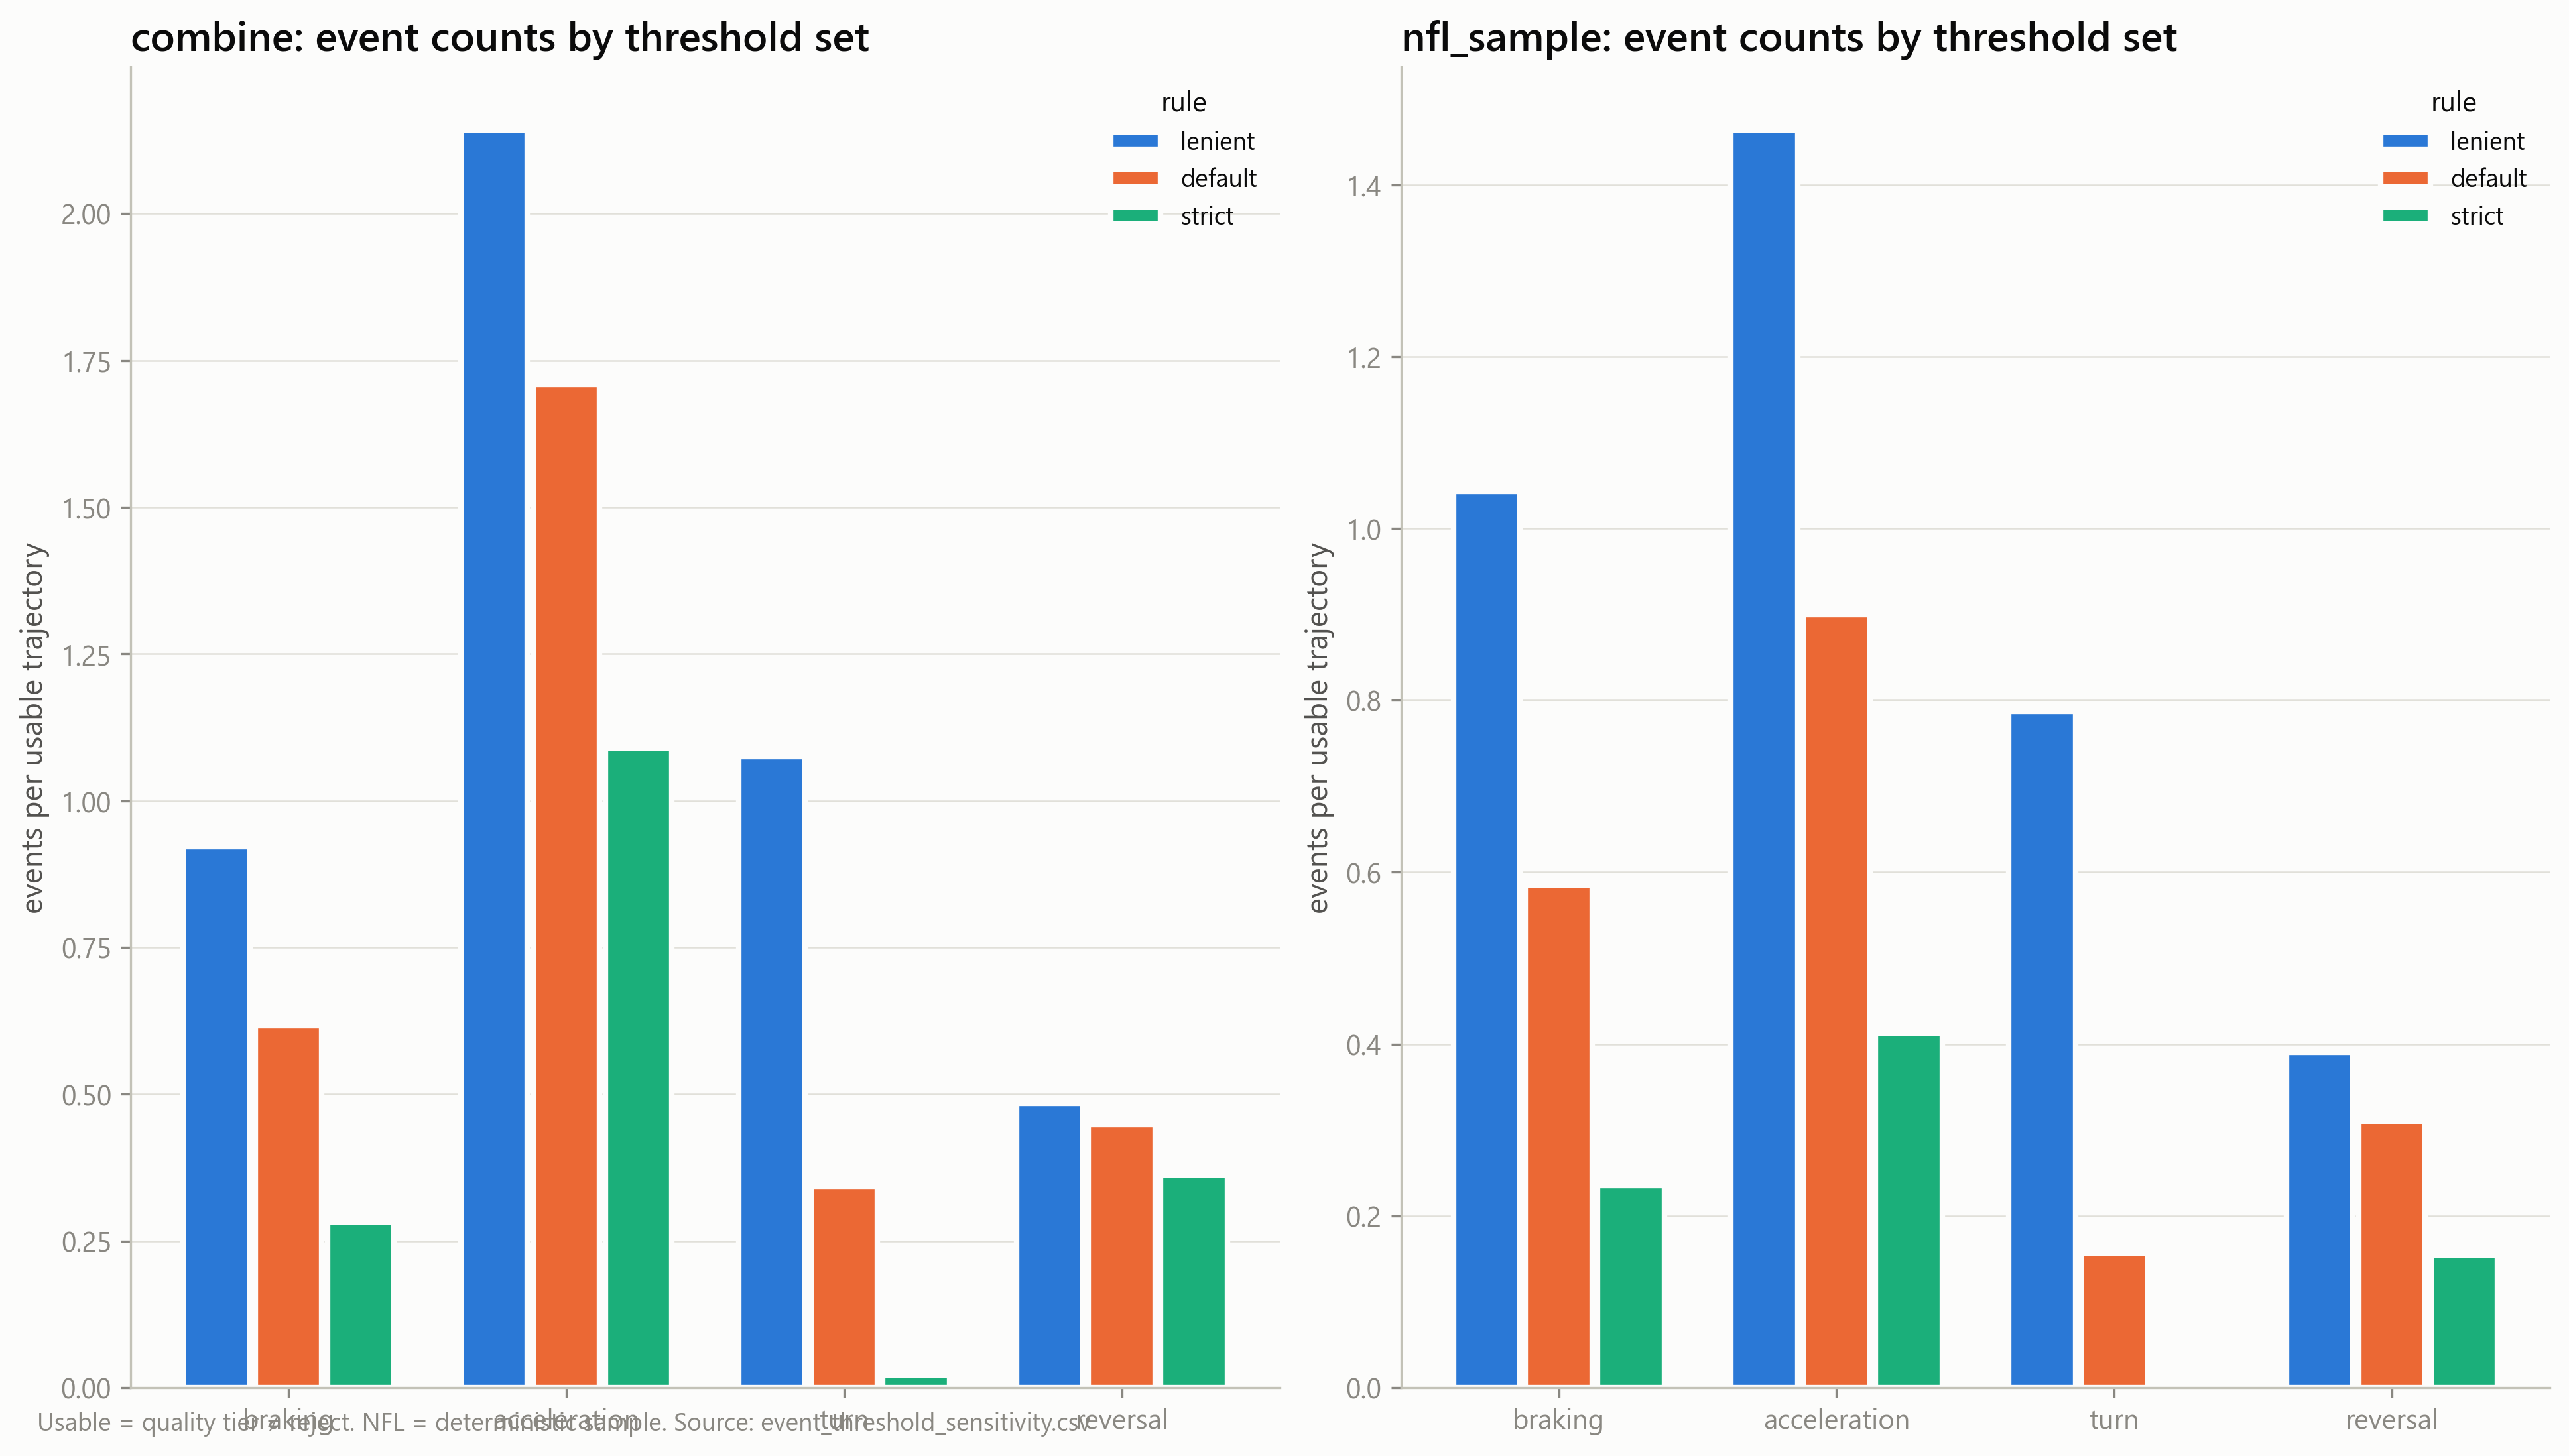

m1_quality_tiers.png


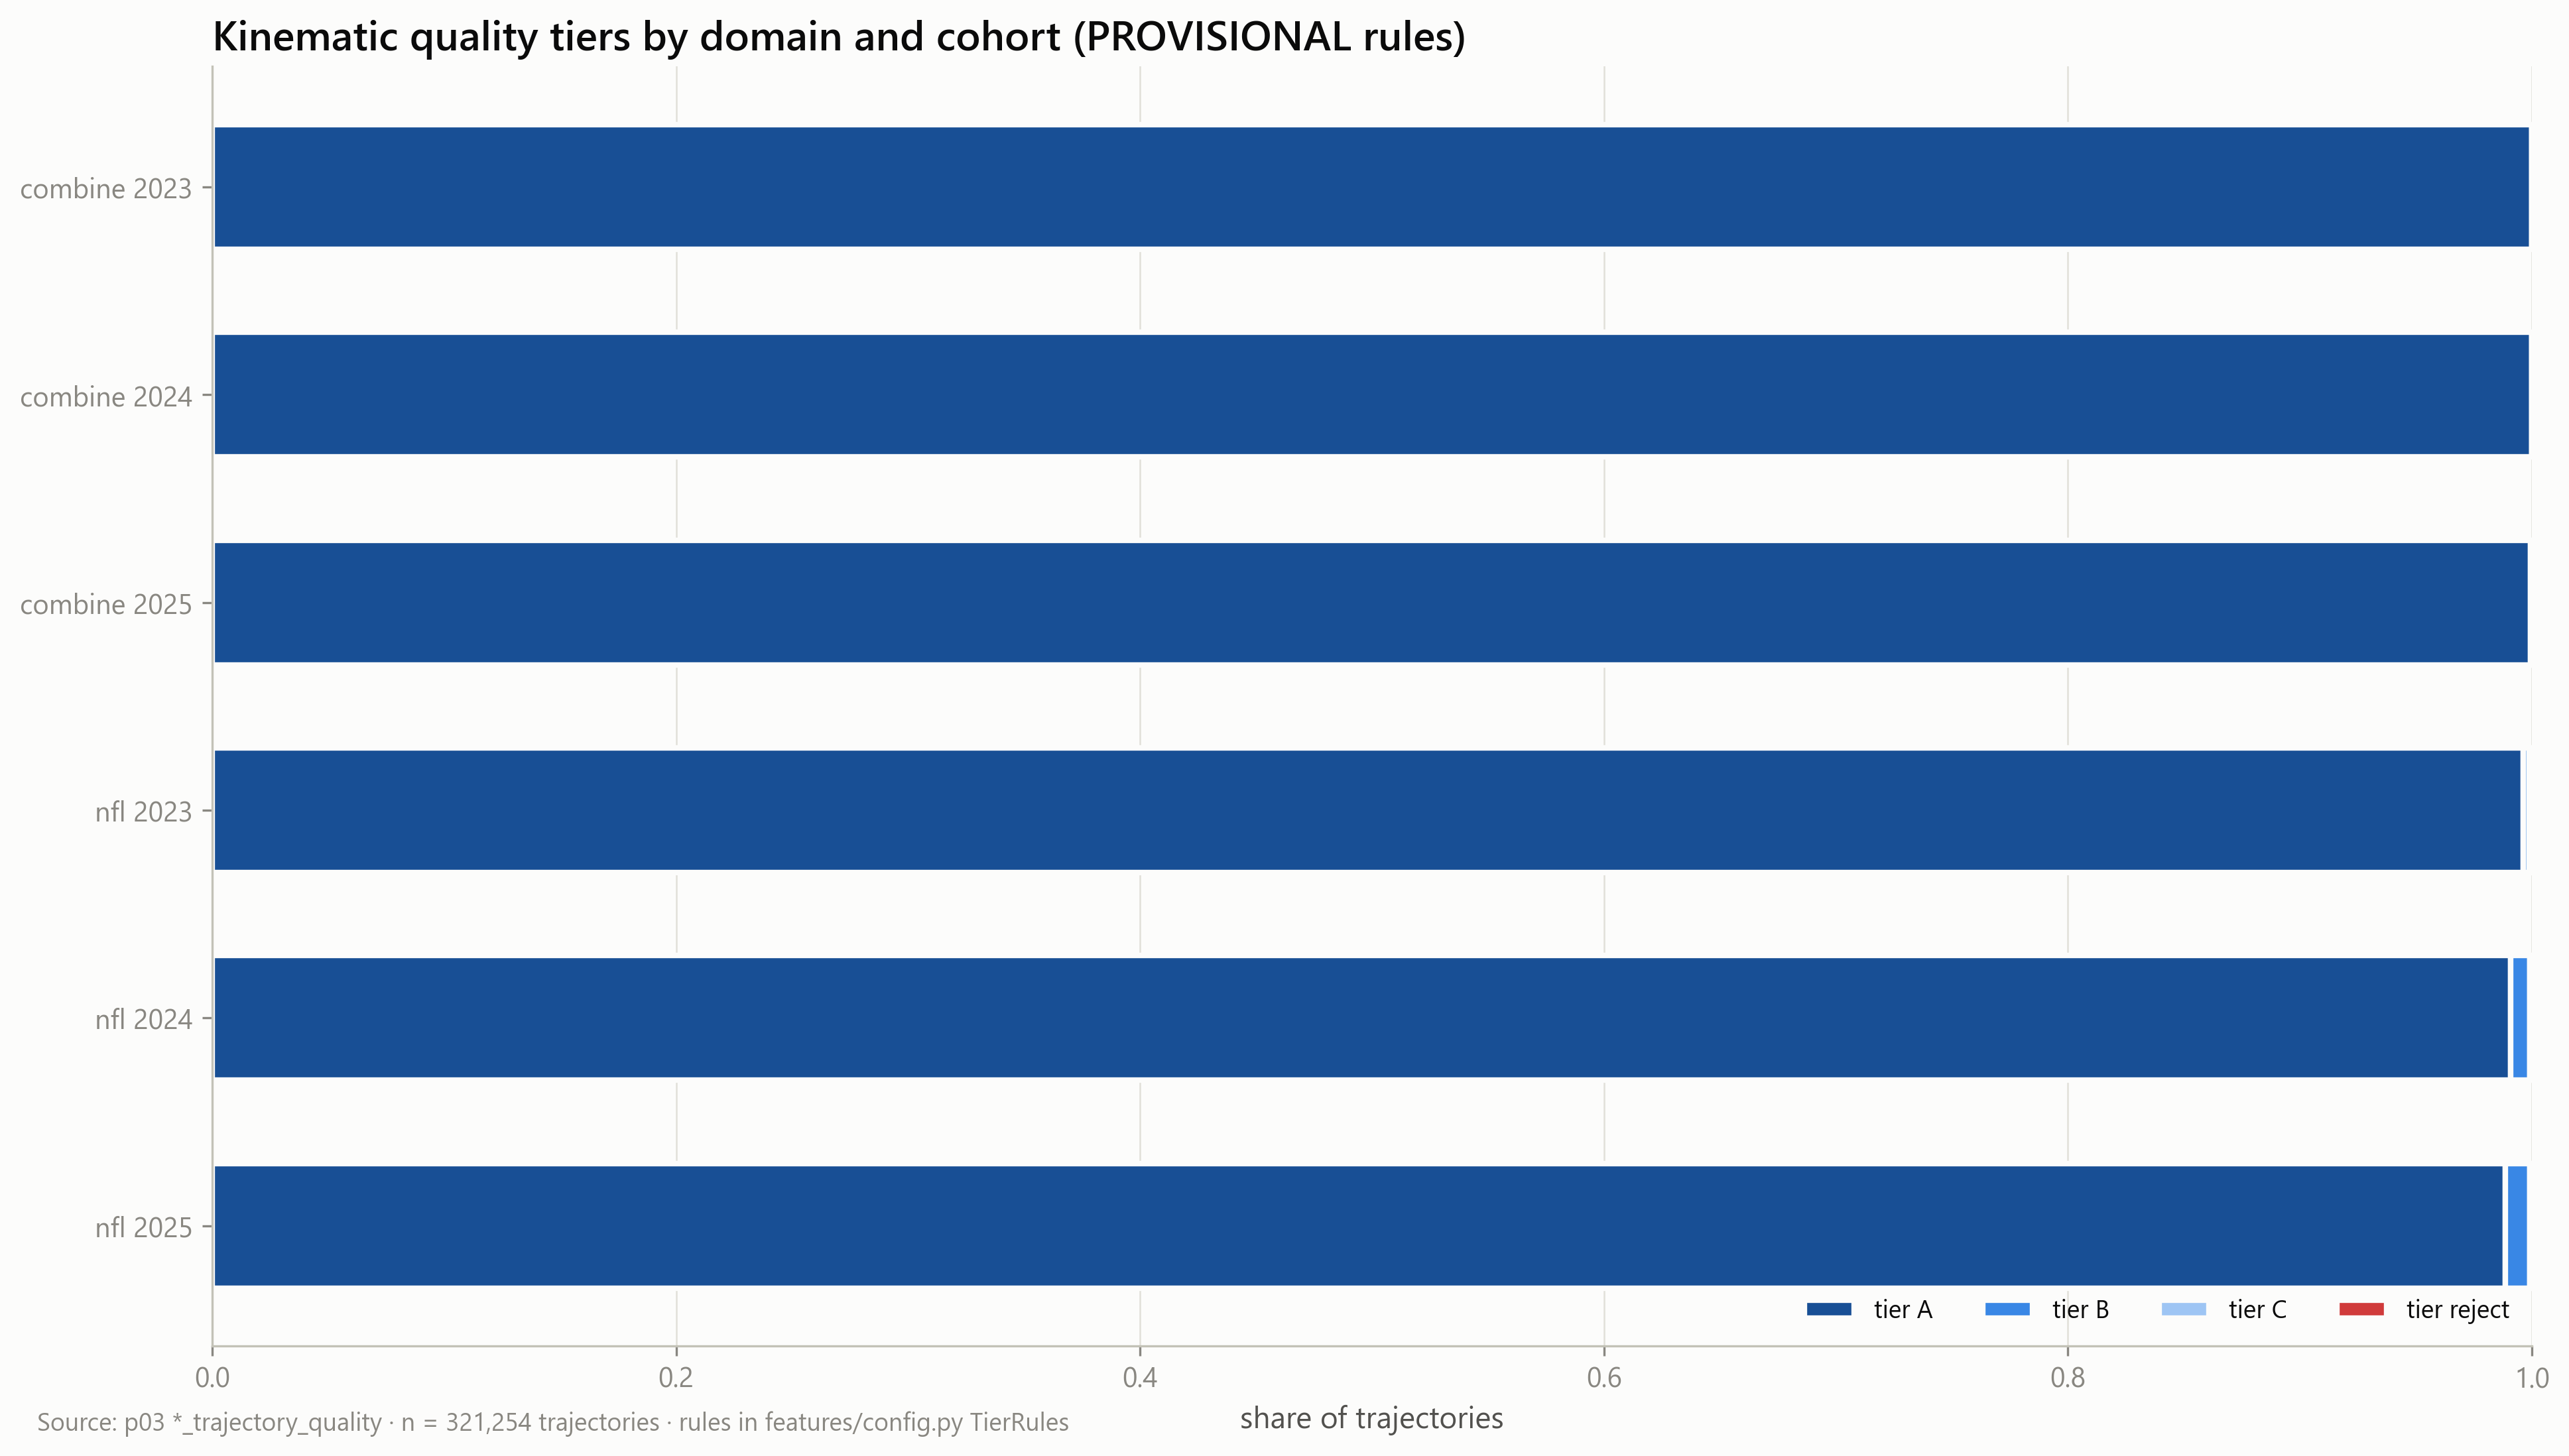

m1_signal_example_forty_yard_dash.png


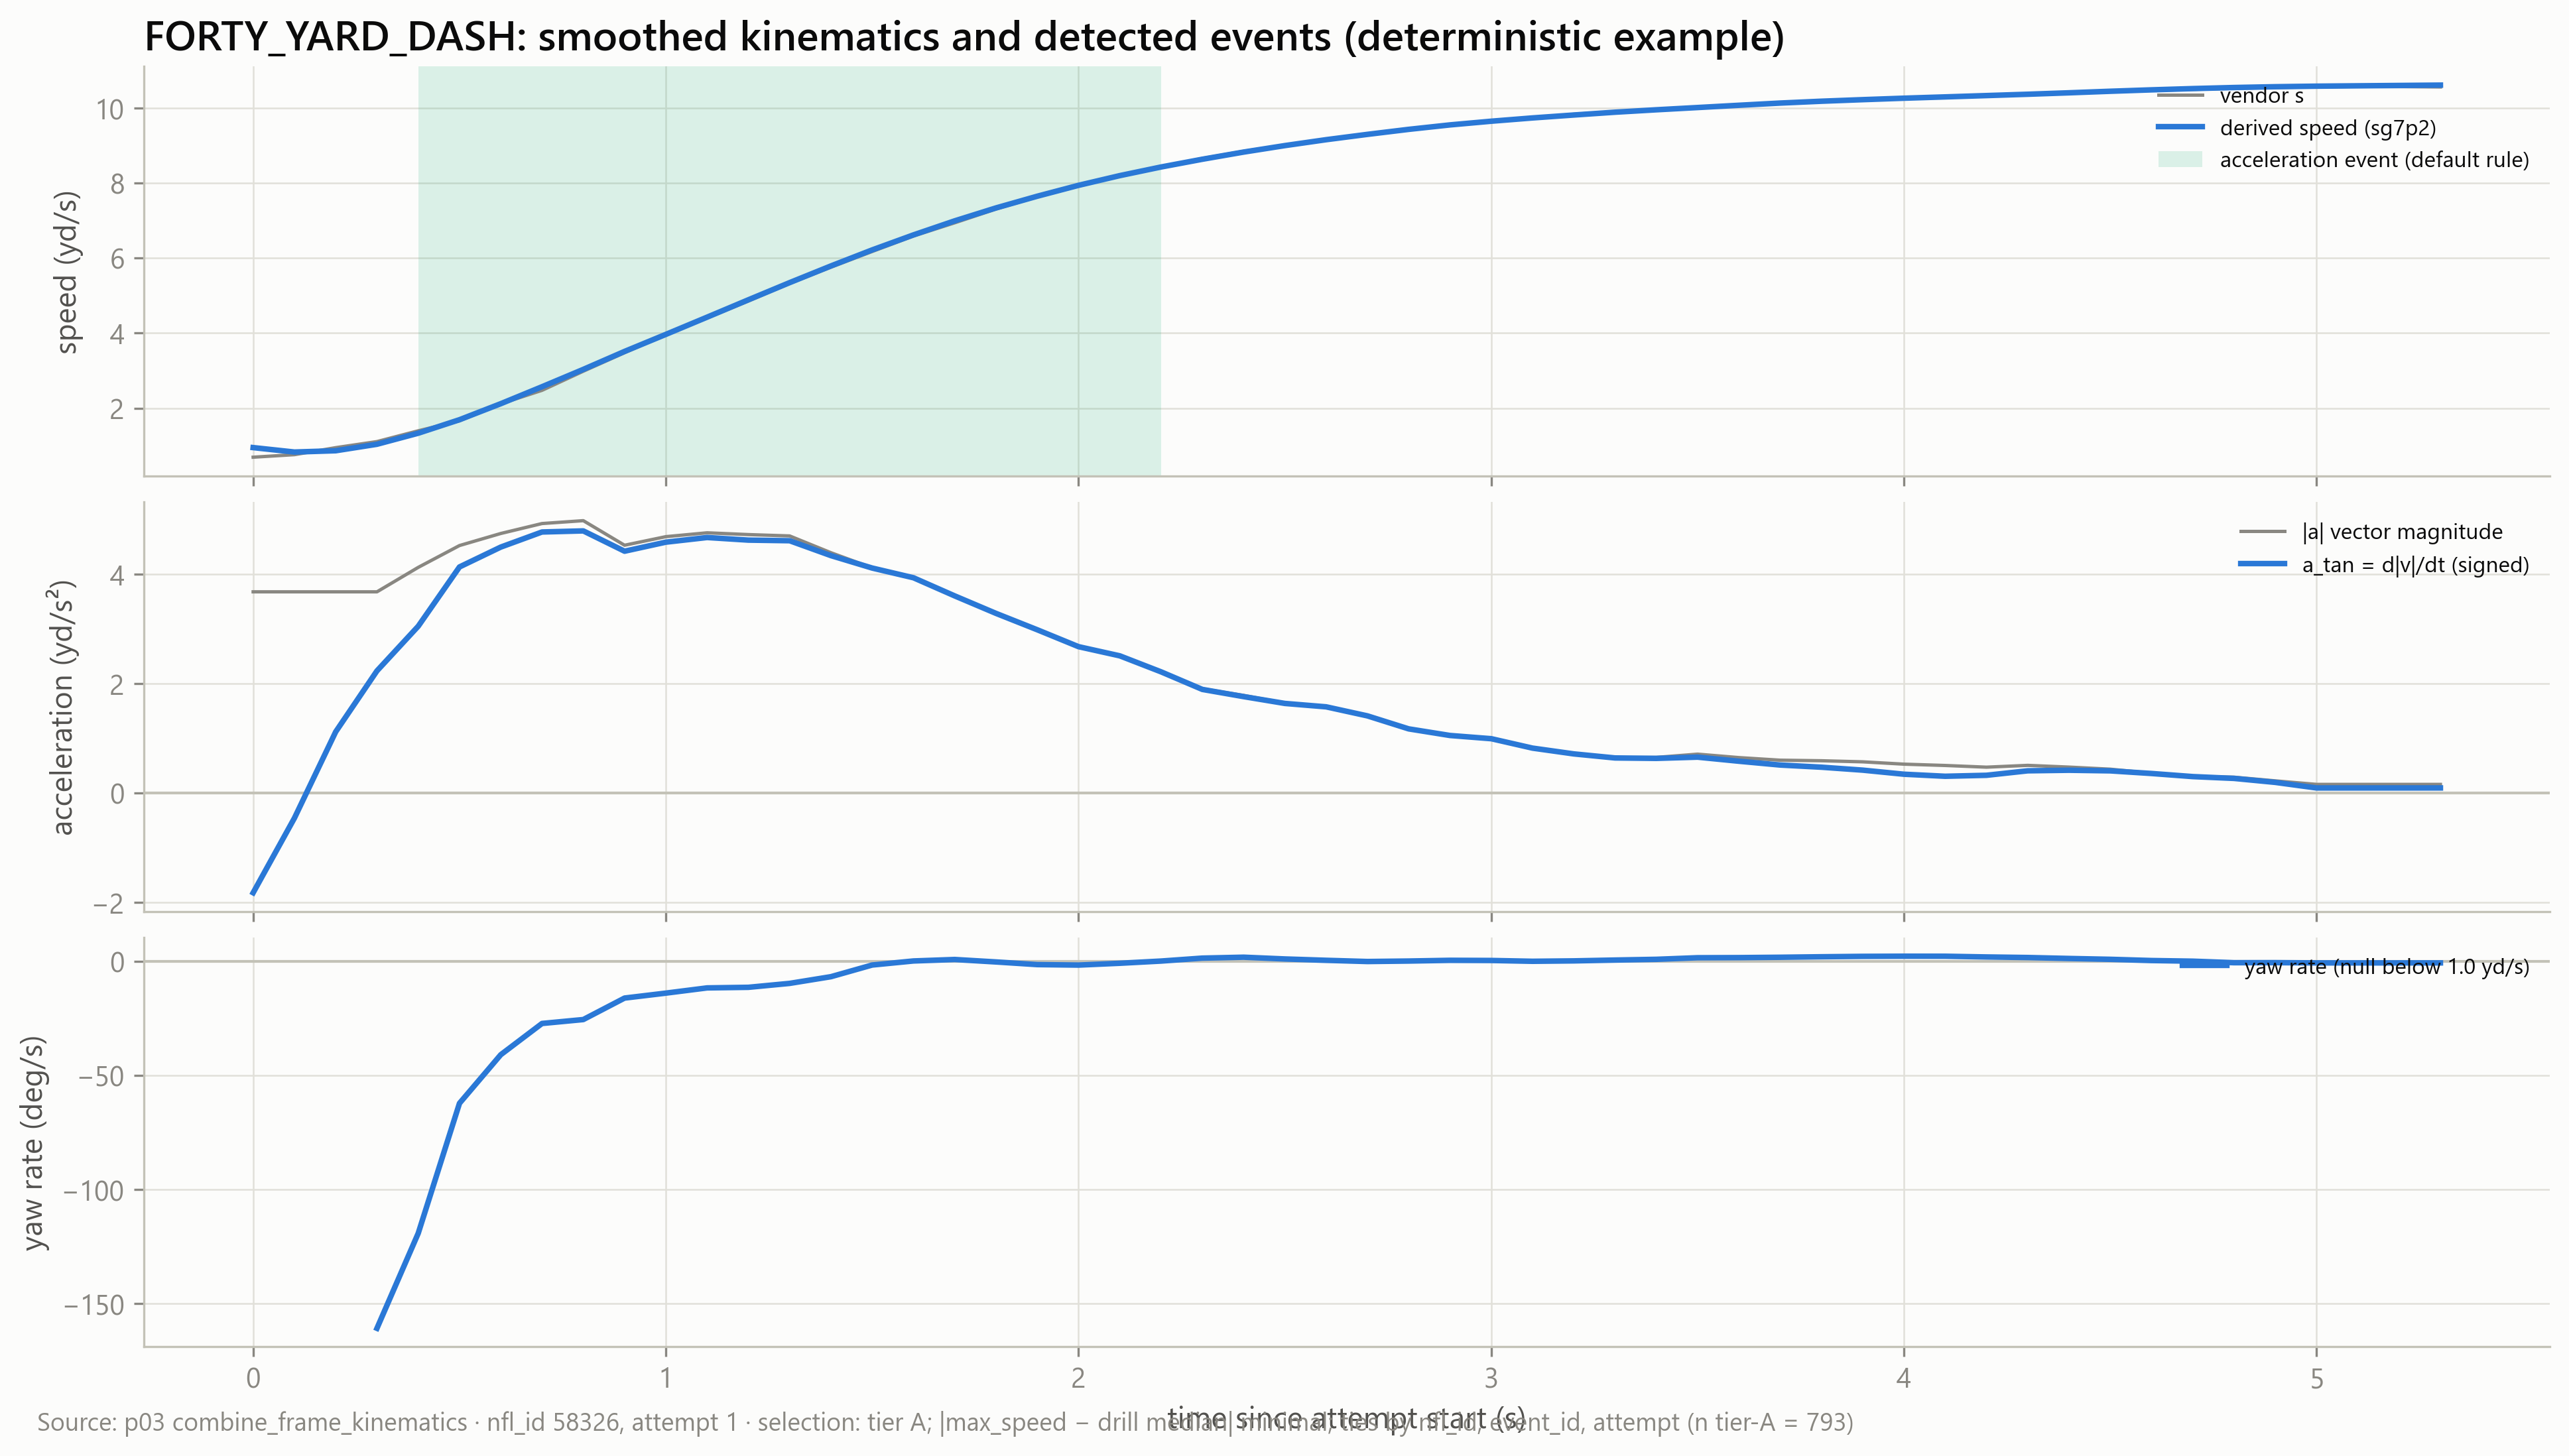

m1_signal_example_short_shuttle.png


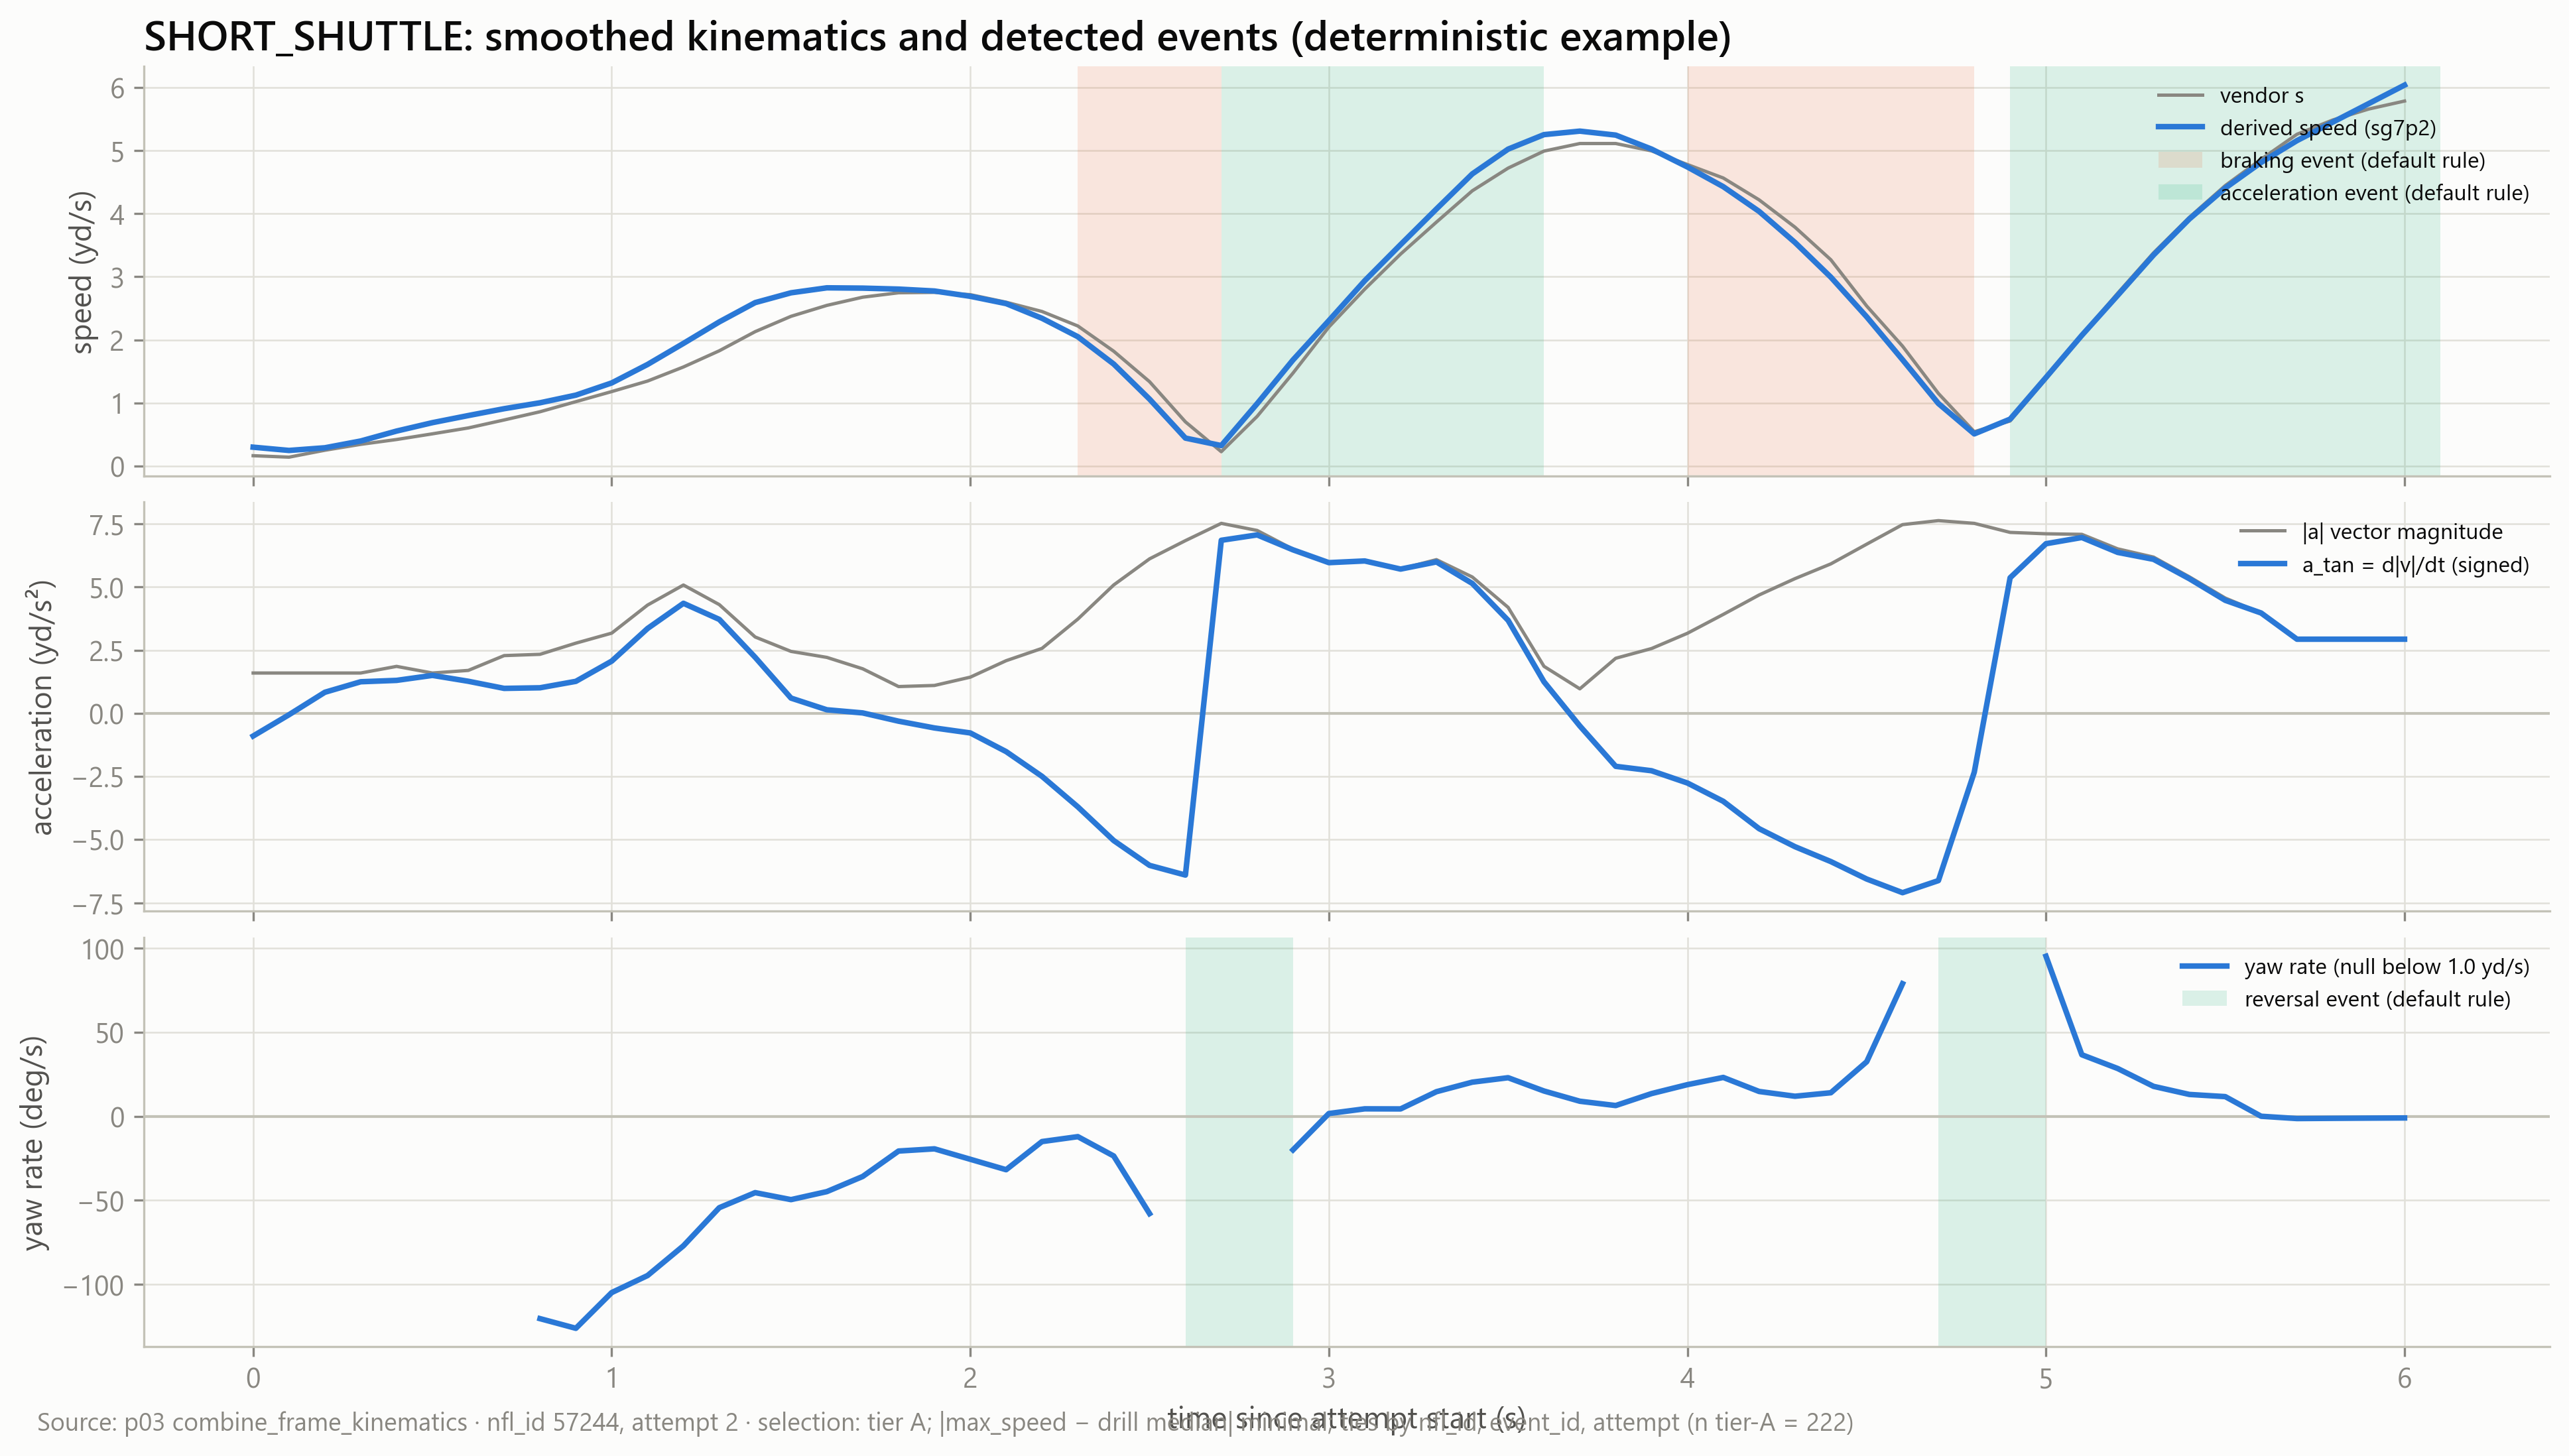

m1_signal_example_three_cone_drill.png


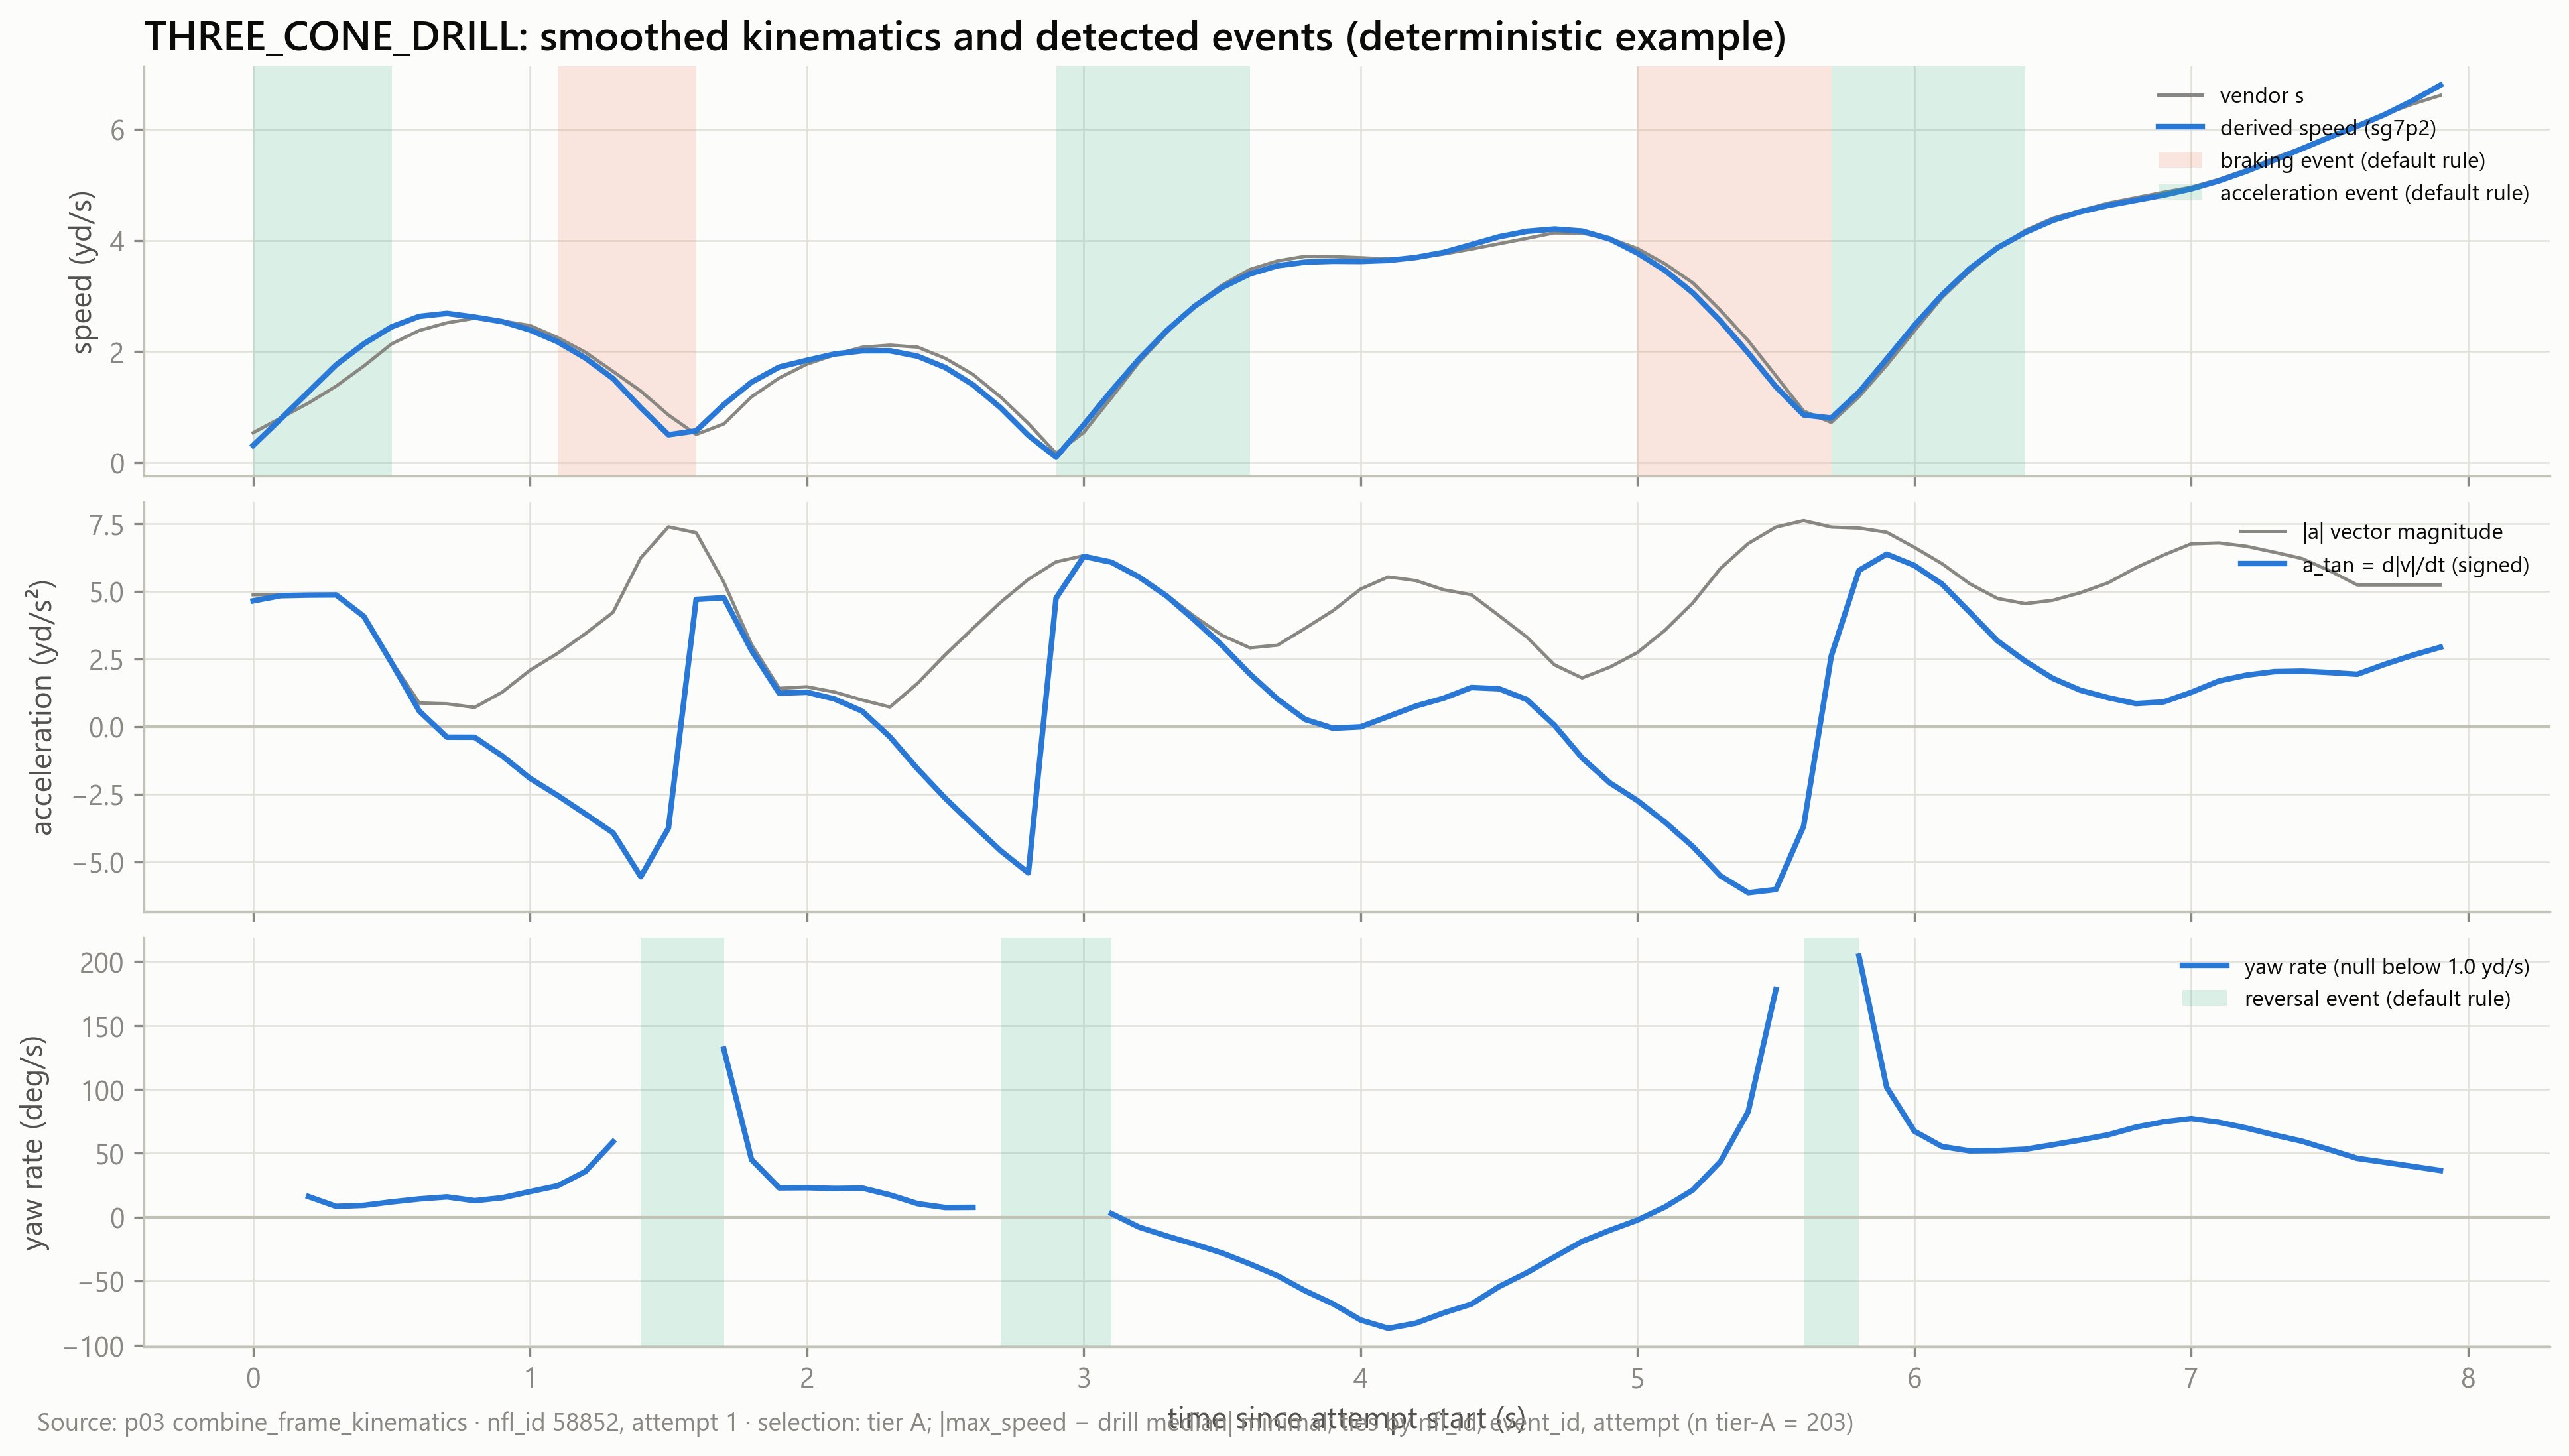

m1_smoothing_sensitivity.png


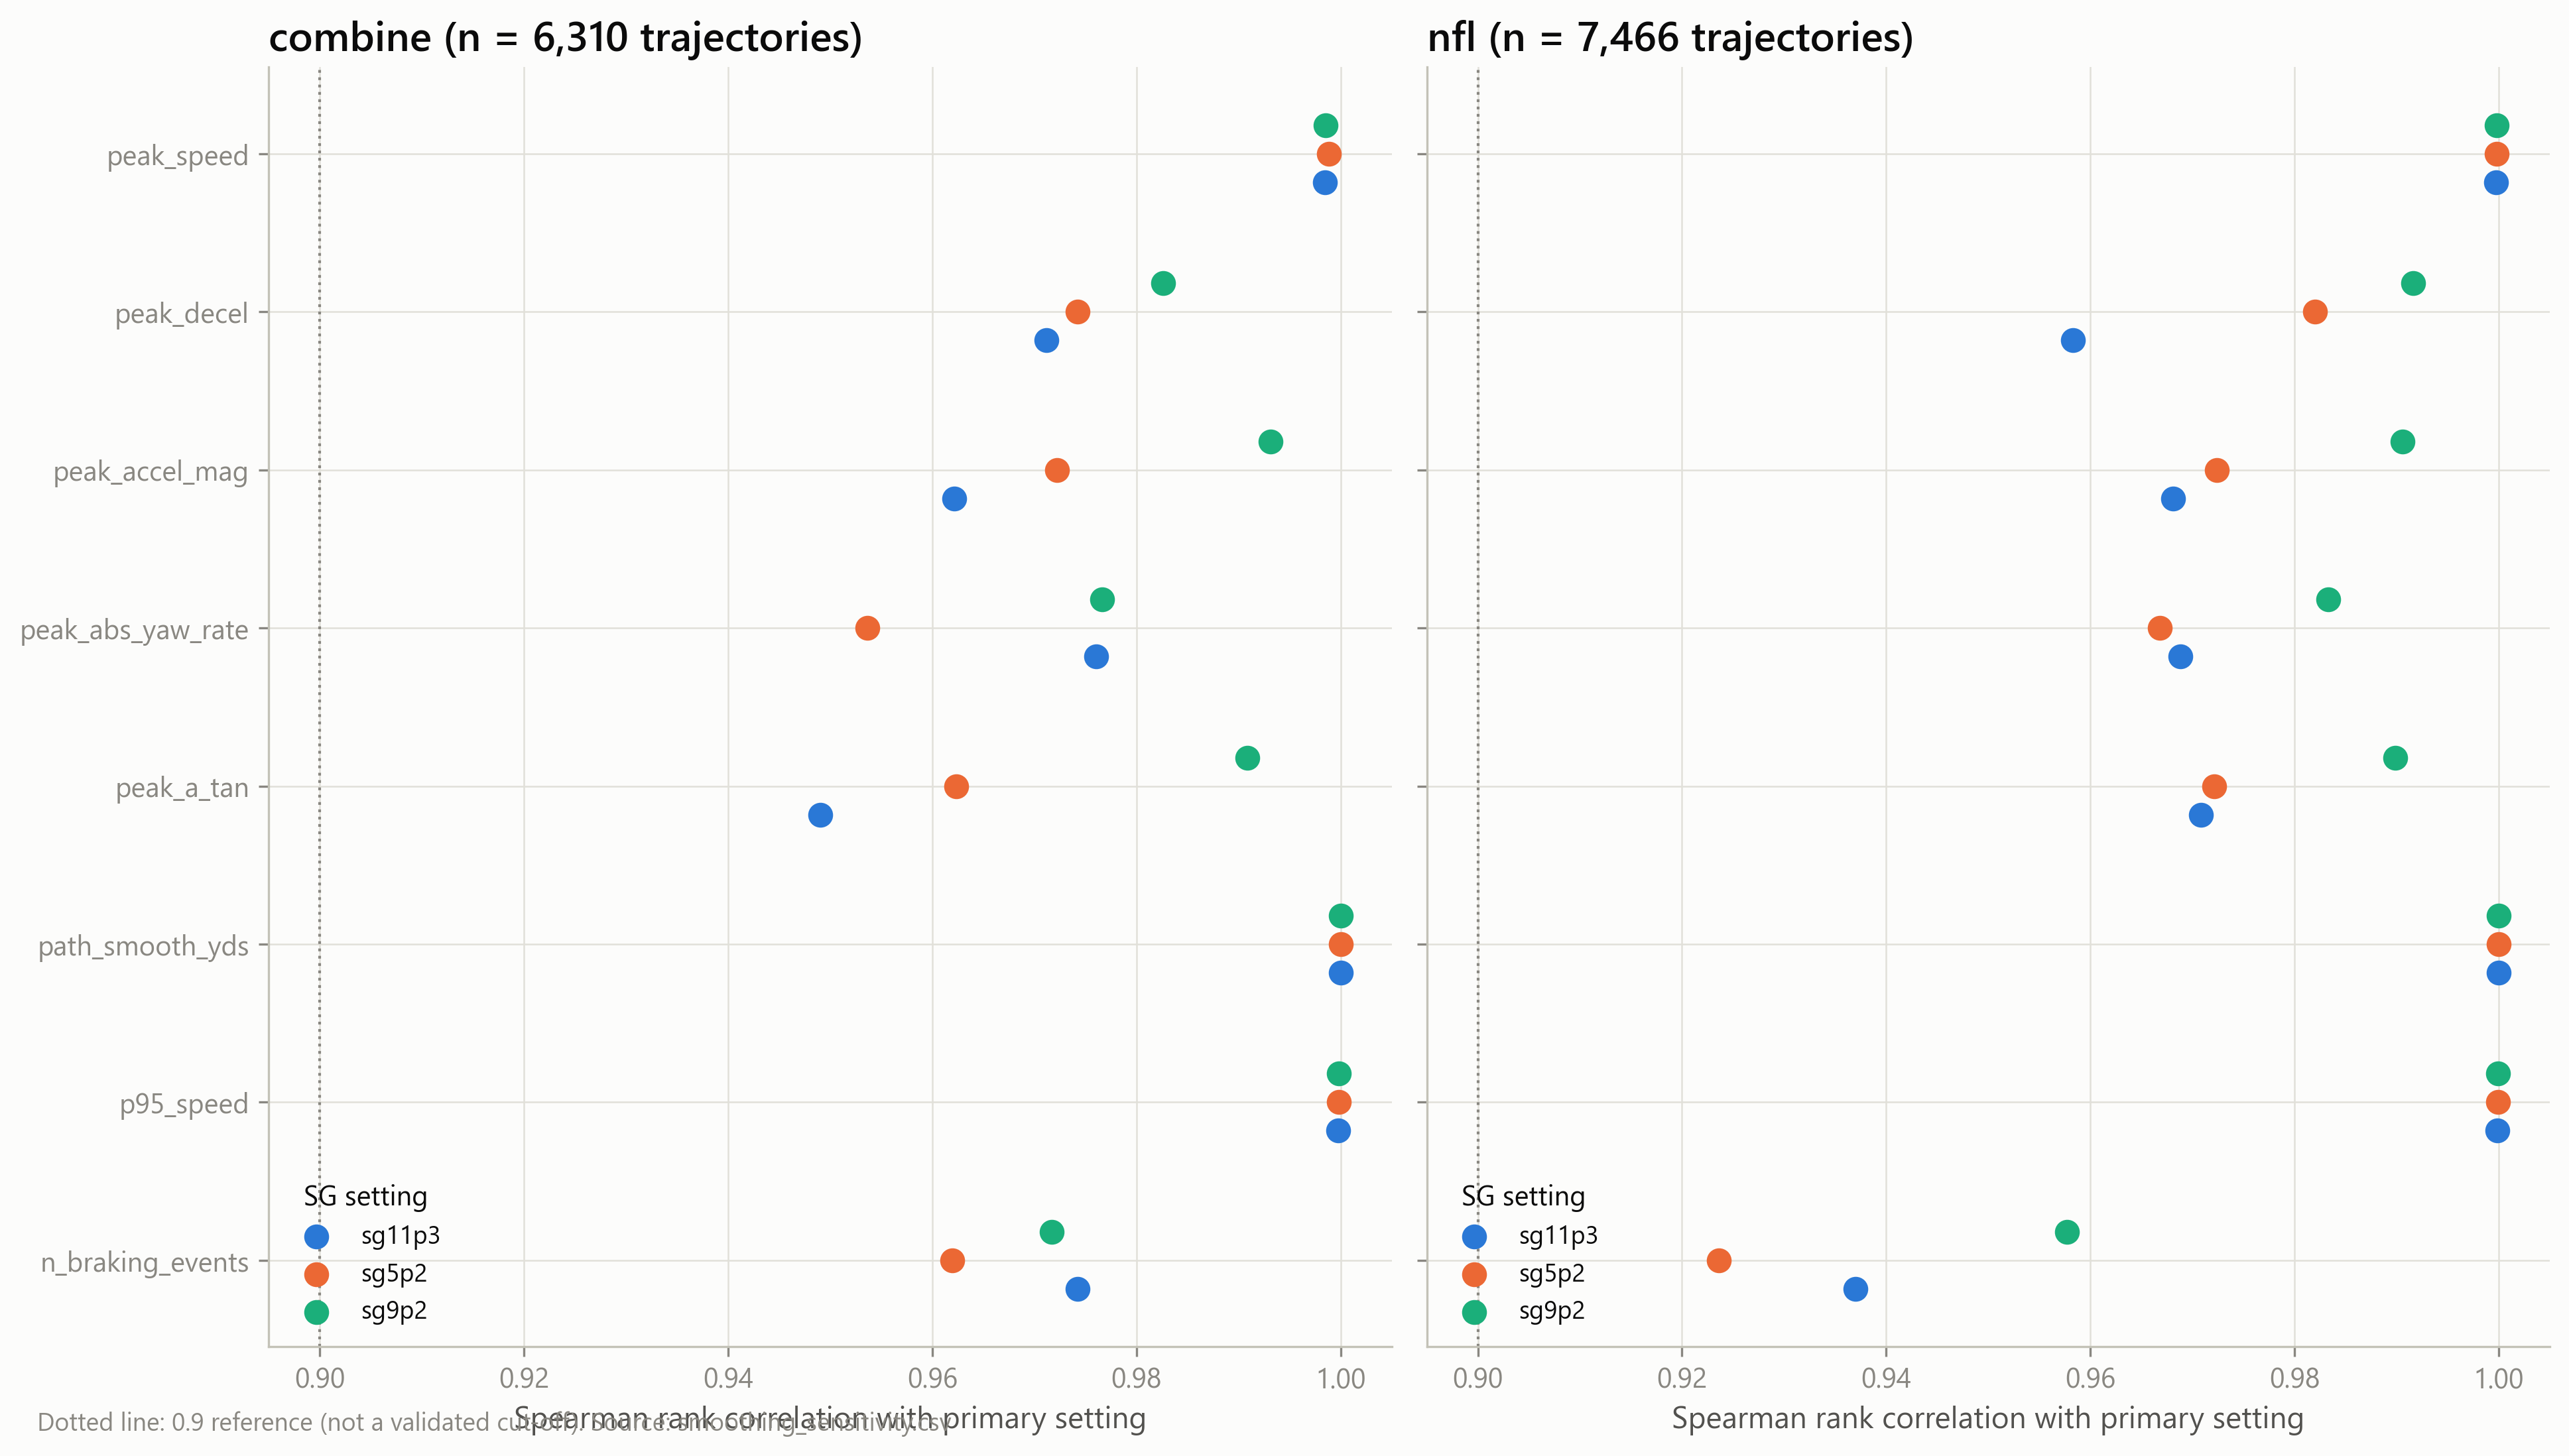

m1_trajectory_events_three_cone.png


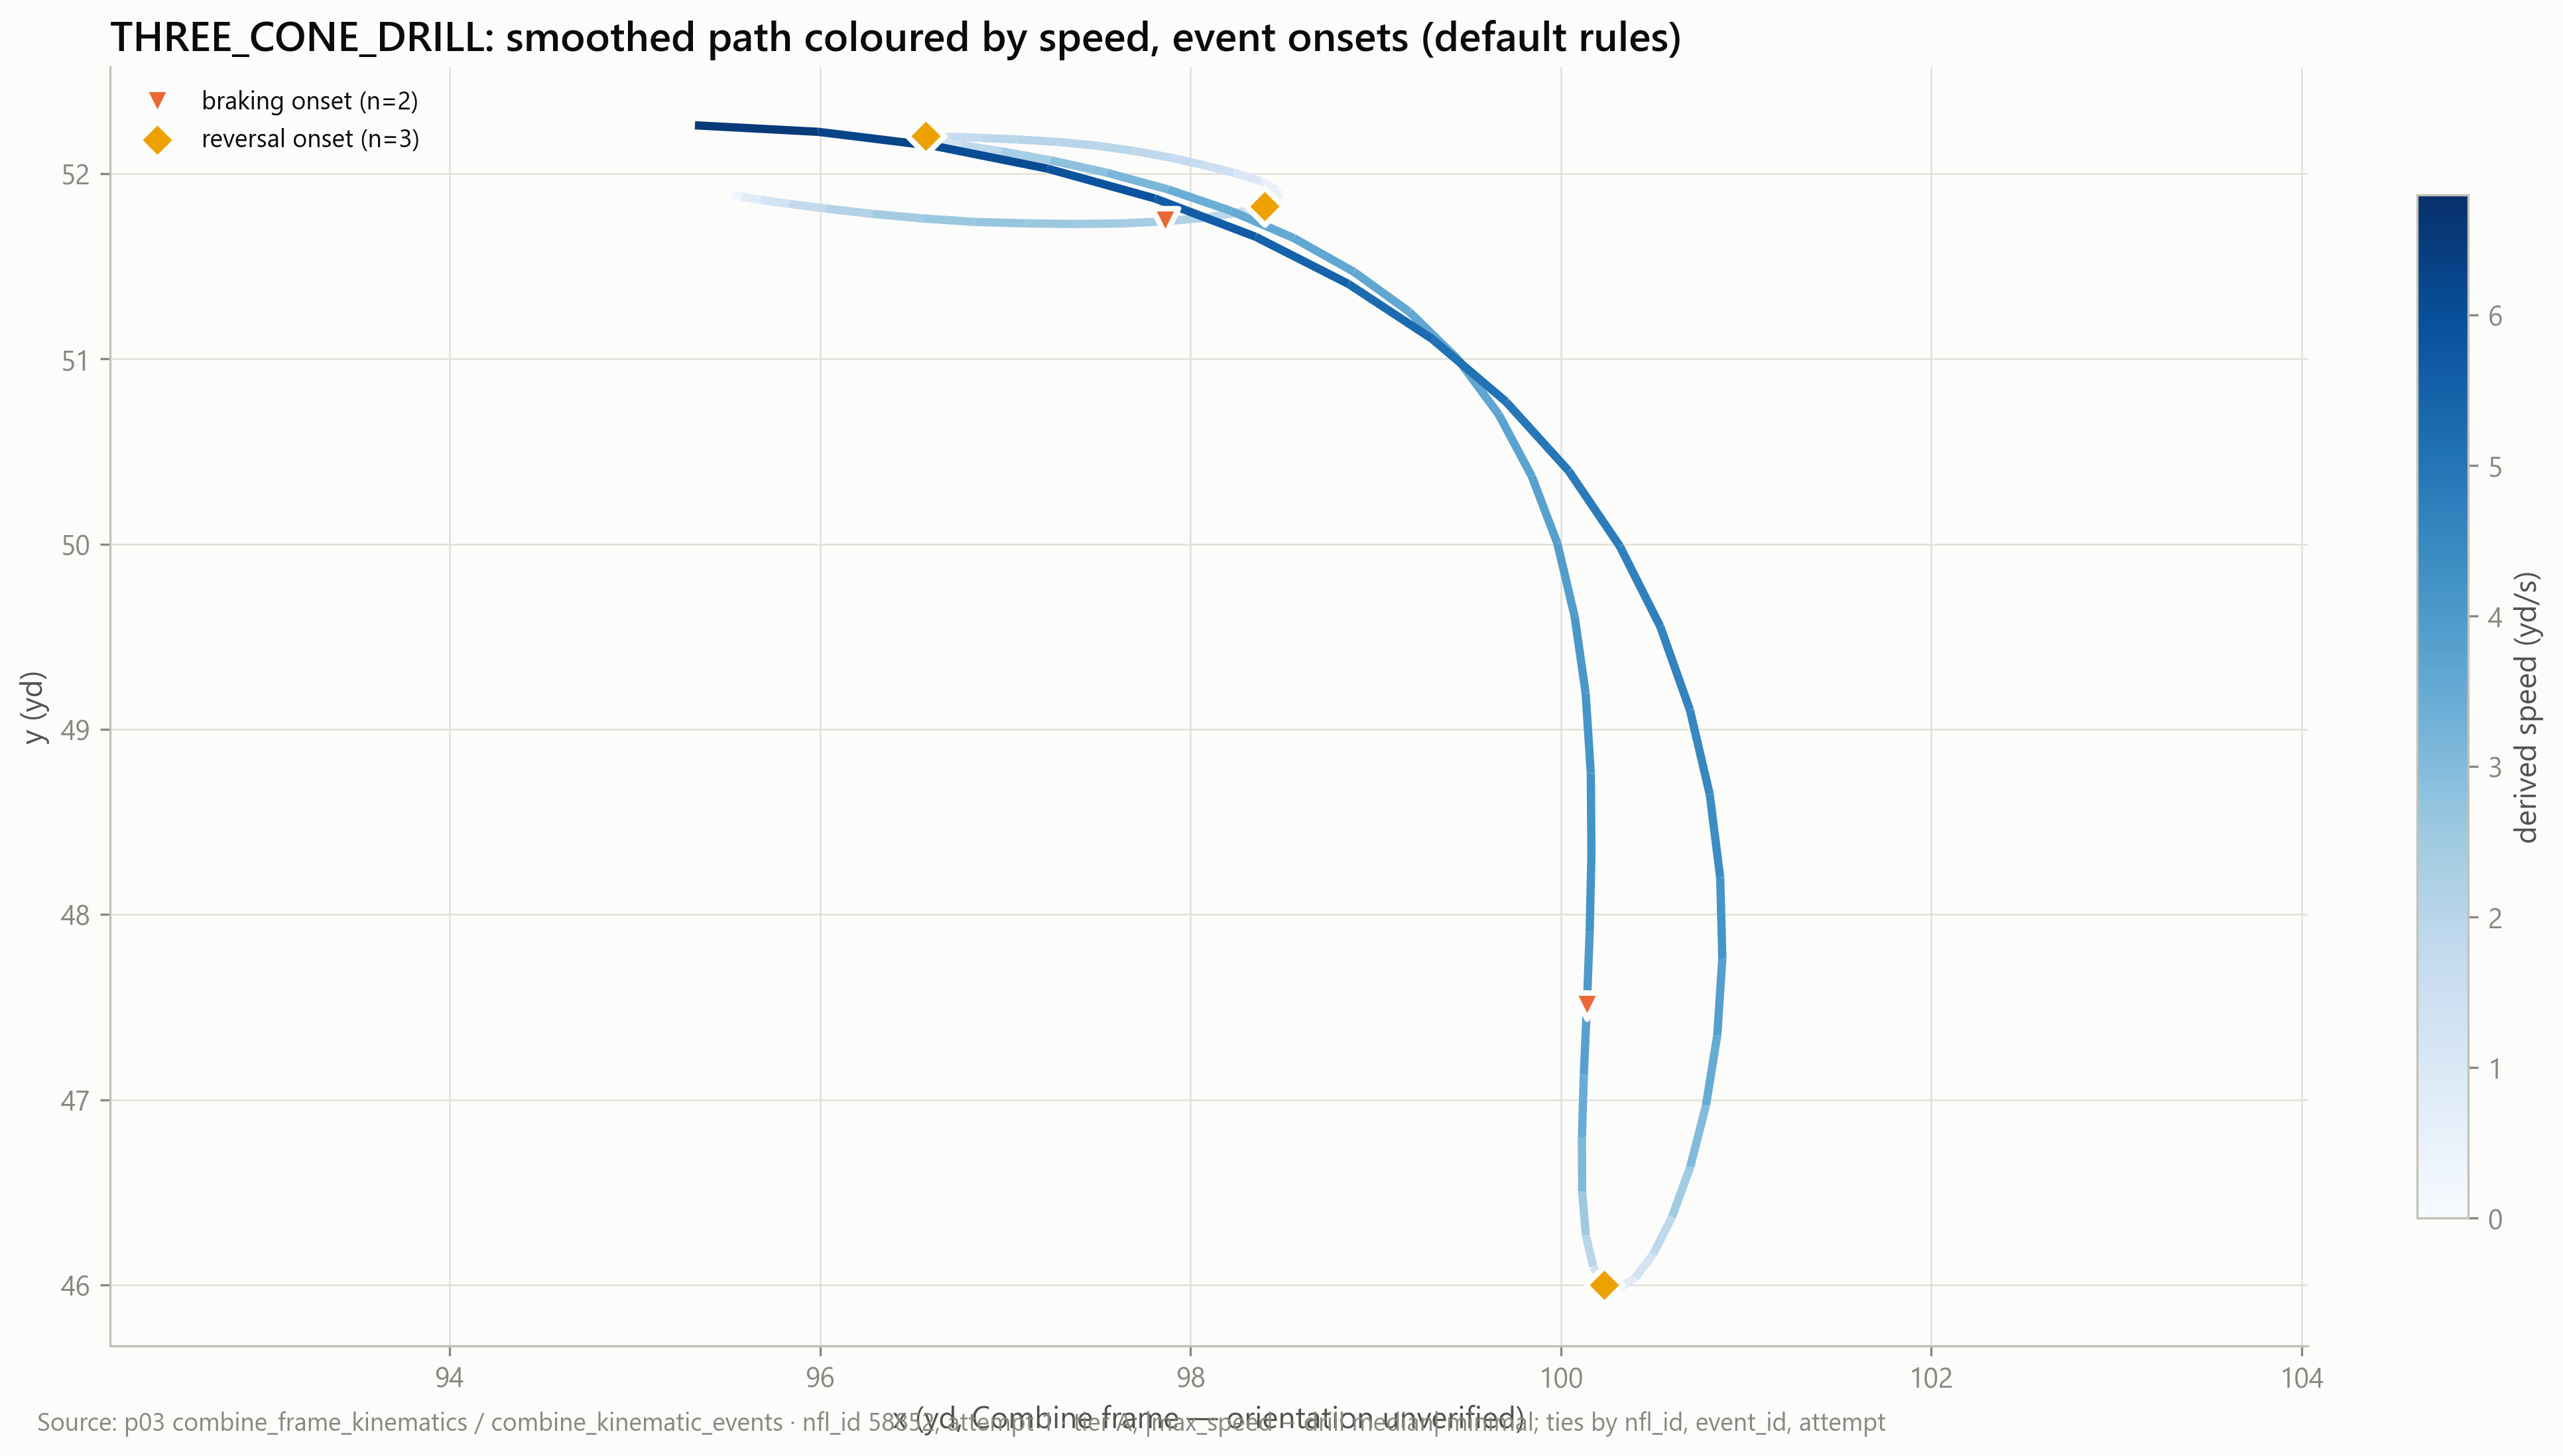

m1_vendor_vs_derived_speed.png


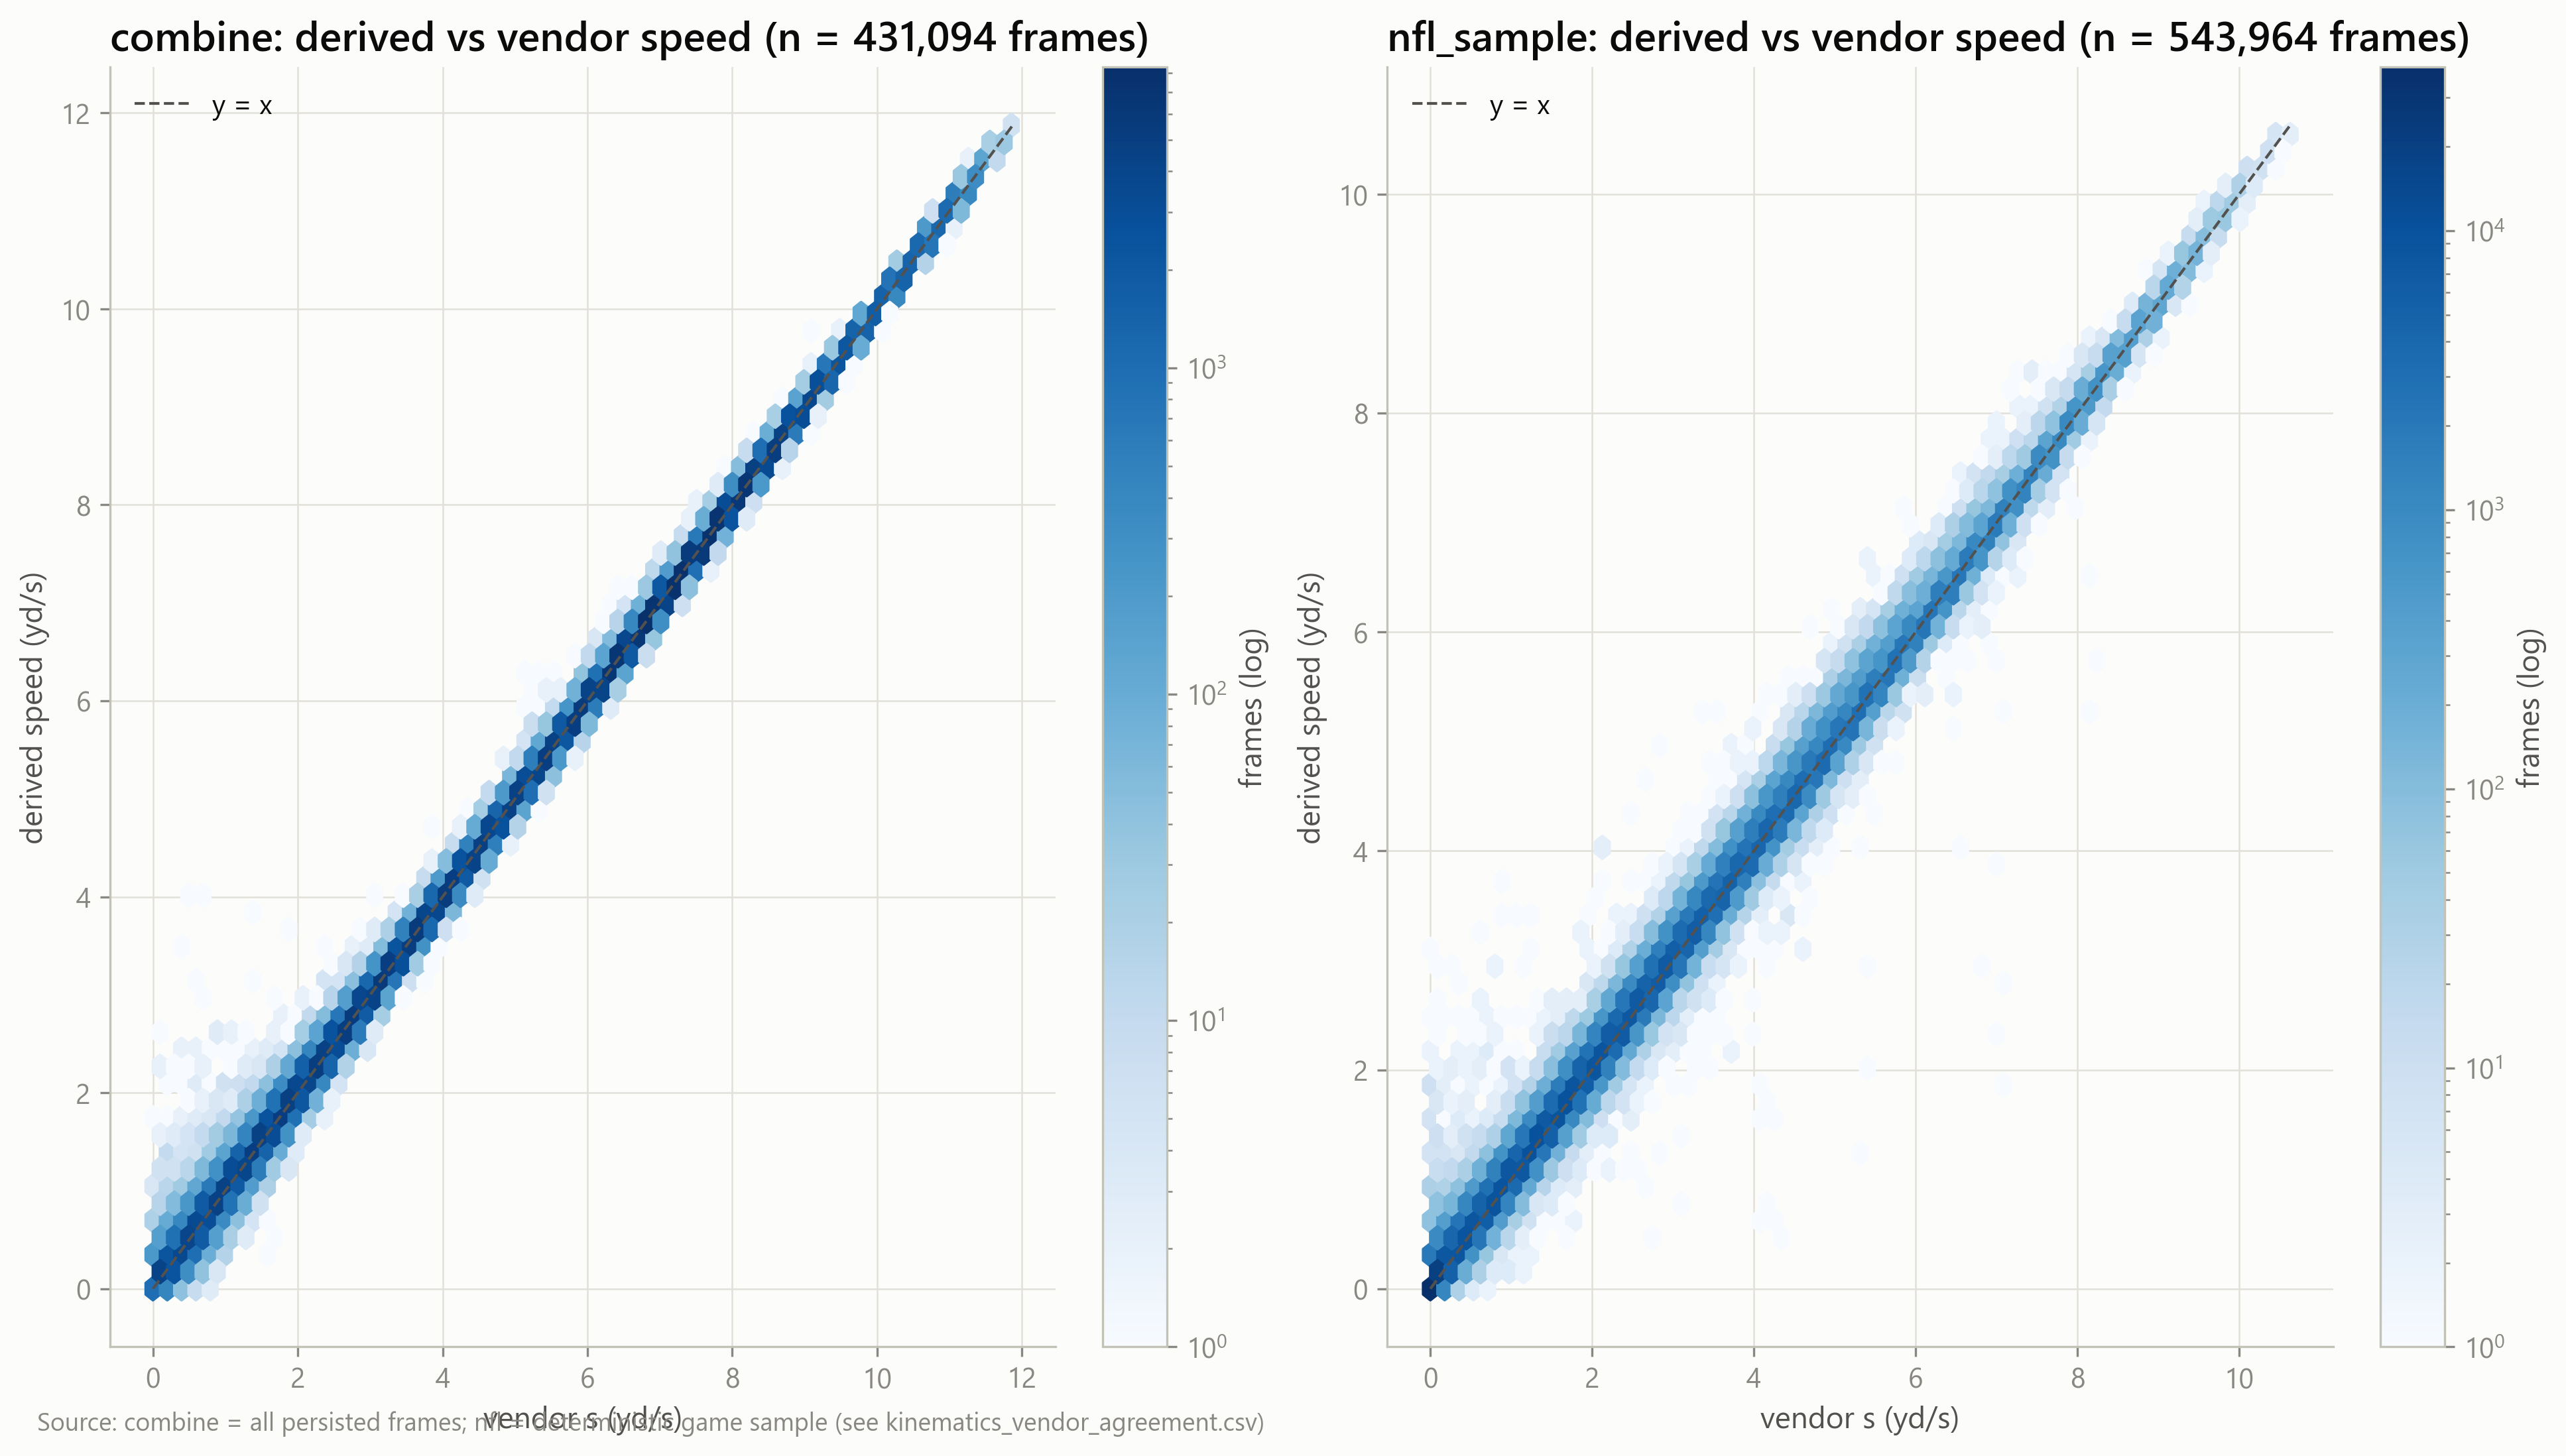

In [6]:
from IPython.display import Image, display
for p in sorted(store.figures_dir.glob('m1_*.png')):
    print(p.name); display(Image(filename=str(p), width=900))

In [7]:
# On-demand NFL play kinematics (no persisted NFL frames): pick a play from the persisted events.
if 'events' in nfl:
    k = nfl['events'].filter(pl.col('event_type') == 'braking').select('game_id', 'play_id', 'nfl_id').head(1).collect()
    if k.height:
        g, p, n = k.row(0)
        play = builder.nfl_play_kinematics(g, p, n)
        display(play.select('t_s', 's', 'speed', 'a_tan', 'yaw_rate').head(20))

t_s,s,speed,a_tan,yaw_rate
f64,f64,f64,f64,f64
0.0,0.0,0.007143,null,null
0.1,0.0,0.011905,null,null
0.2,0.0,0.016667,null,null
0.3,0.0,0.021429,null,null
0.4,0.0,0.021429,null,null
…,…,…,…,…
1.5,1.98,2.176208,5.789302,24.073014
1.6,2.58,2.715606,5.121632,14.579573
1.7,3.13,3.223625,4.582083,13.633915


## 8. Parquet persistence
Persisted by `kinematic_build` via `ArtifactStore(phase='phase_03')` — manifest `warehouse/gold/phase_03/_manifest.json`, sidecars `*.schema.json`, archived versions in `_archive/`.

## 9. Interpretation (fill in ONLY from executed outputs)
* Vendor speed agreement (combine / nfl_sample): _…_
* Vendor `dir` convention best fit: _…_ (if neither convention has a small median difference, record as unresolved)
* Is vendor `a` a magnitude? (`frac_vendor_a_negative`, corr with `accel_mag` vs `|a_tan|`): _…_
* Smoothing sensitivity — features with Spearman < 0.9 vs primary: _…_
* Event threshold sensitivity — event types whose counts change most across rules: _…_
* Quality tiers — share of tier A/B per domain; dominant tier reasons: _…_

## 10. Limitations
* Centered SG is zero-phase (uses future frames) — descriptive, not real-time.
* Combine coordinate frame / handedness unverified → turn direction (ccw/cw) and absolute heading are provisional; magnitudes are frame-invariant.
* Event and tier thresholds are PROVISIONAL until calibrated on the CSVs above.
* NFL events cover the whole tracked window (pre-snap included); play-phase context comes in M3.
* No force/power estimates (no validated mass/drag model).

## 11. Next analysis
M2 — Combine movement analytics: forty-yard dash decomposition, agility (shuttle / three-cone) turn and braking features, drill-specific features, attempt reliability (notebooks 03 and 06).